---
title: "Pivoted LU decomposition"
subtitle: "Lecture 14: Chapter 5: Linear systems of equations"
code-fold: true
format:
  html: default
  pdf: default
---

{{< include ../extras/_lecture-header.html >}}

In [19]:
# | code-fold: true

using Plots, LaTeXStrings, LinearAlgebra

function forwardSub(L, b)
    n = size(L,1)
    y = zeros(n)
    y[1] = b[1] / L[1, 1]
    for i ∈ 2:n
        s = sum(L[i, j] * y[j] for j ∈ 1:i-1)
        y[i] = (b[i] - s) / L[i, i]
    end
    return y
end

function backwardSub(U, y)
    n = size(U, 1)
    x = zeros(n)
    x[n] = y[n] / U[n, n]
    for i ∈ n-1:-1:1
        s = sum(U[i, j] * x[j] for j ∈ i+1:n)
        x[i] = (y[i] - s) / U[i, i]
    end
    return x
end

backwardSub (generic function with 1 method)

## Previously.....

- Cramer's rule requires $O(n!)$ operations: far too expensive,
- Gaussian elimination (elementary row operations) requires $O(n^3)$ operations,
- If $L$ is unit lower triangular and $U$ is upper triangular, then we solve $LUx = b$ by solving $Ly = b$ (forwards substitution) and then $Ux = y$ (backwards substitution): this requires $O(n^2)$ operations.

## Computing LU decomposition

Algorithm: set $A^{(1)} := A$ and, for $k = 1, \dots, n$, let $u_k$ be the $k$-th row of $A^{(k)}$, $\ell_k$ the $k$-th column of $A^{(k)}$ divided by $(u_k)_k$, and 
$$
\begin{align}
    A^{(k+1)} := A^{(k)} - \ell_k u_k.
\end{align}
$$
Then $A = LU$ where $L$ has columns $\ell_k$ and $U$ has rows $u_k$.



In [20]:
function LU_decomp( A )
    n = size(A, 1)      
    L = diagm(ones(n))  
    U = zeros(n, n)

    for j ∈ 1:n-1
        U[j, :] = A[j, :]
        L[:, j] = A[:, j] / U[j, j]
        A = A - L[:, j] * U[j, :]'
    end
    U[n, n] = A[n, n]

    return tril(L), triu(U)
end

A = [ 2 0 4 3 ; -4 5 -7 -10 ; 1 15 2 -9/2; -2 0 2 -13]
(L, U) = LU_decomp(A)

display( L )
display( U ) 

4×4 Matrix{Float64}:
  1.0  0.0   0.0  0.0
 -2.0  1.0   0.0  0.0
  0.5  3.0   1.0  0.0
 -1.0  0.0  -2.0  1.0

4×4 Matrix{Float64}:
 2.0  0.0   4.0   3.0
 0.0  5.0   1.0  -4.0
 0.0  0.0  -3.0   6.0
 0.0  0.0   0.0   2.0

::: {#exr-l13-warmup name="Warm-up"}

Use LU decomposition combined with forward and backwards substitution to solve the linear system of equations

$$
\begin{align}
\begin{pmatrix}
2 & 3 & 4 \\
4 & 5 & 10 \\
4 & 8 & 2
\end{pmatrix}
\begin{pmatrix}
x\\y\\z
\end{pmatrix}
= \begin{pmatrix}
1 \\ 0 \\ -1
\end{pmatrix}. \nonumber
\end{align}
$$

::: {.exercise-solution .draft style="display: none;"}

*Step 1.* $u_1 = (2,3,4)$ and $\ell_1 = (1, 2, 2)^\intercal$ (the first column divided by $2$). Then
$$
A^{(2)} = A - \ell_1 u_1 = \begin{pmatrix} 2&3&4\\4&5&10\\4&8&2\end{pmatrix} - \begin{pmatrix} 2&3&4\\4&6&8\\4&6&8\end{pmatrix} = \begin{pmatrix} 0&0&0\\0&-1&2\\0&2&-6\end{pmatrix}.
$$
*Step 2.* $u_2 = (0,-1,2)$ and $\ell_2 = (0, 1, -2)^\intercal$ (the second column divided by $-1$), so that $A^{(3)} = A^{(2)} - \ell_2 u_2 = \mathrm{diag}(0,0,-2)$.

*Step 3.* $u_3 = (0,0,-2)$ and $\ell_3 = (0,0,1)^\intercal$. Hence
$$
L = \begin{pmatrix} 1&0&0\\2&1&0\\2&-2&1\end{pmatrix},\qquad U = \begin{pmatrix} 2&3&4\\0&-1&2\\0&0&-2\end{pmatrix}.
$$

*Forwards substitution* ($Ly = b$): $y_1 = 1$, $y_2 = 0 - 2y_1 = -2$, $y_3 = -1 - 2y_1 + 2y_2 = -7$.

*Backwards substitution* ($U(x,y,z)^\intercal = (y_1,y_2,y_3)^\intercal$): $z = \frac{-7}{-2} = \frac72$, then $-y + 2z = -2$ gives $y = 9$, and $2x + 3y + 4z = 1$ gives $x = \frac{1 - 27 - 14}{2} = -20$.

So $(x,y,z) = (-20, 9, \frac72)$. Julia's `lu(A)` (below) returns a *different* factorisation because it pivots (see below): it chooses the largest entry, $4$, in the first column as the first pivot.

:::

:::

In [21]:
A = [2 3 4 ; 4 5 10 ; 4 8 2]
b = [1; 0 ; -1]
(L, U) = LU_decomp(A) 

y = forwardSub(L, b)
x = backwardSub(U, y)

3-element Vector{Float64}:
 -20.0
   9.0
   3.5

We can use Julia's `A \ b` which is described as follows:

> "Matrix division using a polyalgorithm. For input matrices `A` and `B`, the result `X` is such that `AX = B` when `A` is square. The solver that is used depends upon the structure of `A`. If `A` is upper or lower triangular (or diagonal), no factorization of `A` is required and the system is solved with either forward or backward substitution. For non-triangular square matrices, an LU factorization is used."

In [22]:
A \ b 

3-element Vector{Float64}:
 -20.00000000000002
   9.000000000000009
   3.5000000000000036

::: {#exr-l12-lu-by-hand}

[](../exercises/bank.html#bank-exr-l12-lu-by-hand)

Compute the $LU$ decomposition of 
$$
\begin{align*}
    A = \begin{pmatrix} 1 & 2 & -3 \\ 0 & 1 & -1 \\ 1 & 1 & 0 \end{pmatrix}
\end{align*}
$$
by hand, and check your answer with `LU_decomp`.

::: {.exercise-solution .draft style="display: none;"}

Step 1: $\mathbf u_1 = (1, 2, -3)$ (first row) and $\mathbf l_1 = (1, 0, 1)^\intercal$ (first column divided by $u_{11} = 1$). Then
$$
\begin{align*}
    A - \mathbf l_1 \mathbf u_1 = \begin{pmatrix} 0 & 0 & 0 \\ 0 & 1 & -1 \\ 0 & -1 & 3 \end{pmatrix}.
\end{align*}
$$
Step 2: $\mathbf u_2 = (0, 1, -1)$ and $\mathbf l_2 = (0, 1, -1)^\intercal$, leaving $u_{33} = 3 - 1 = 2$. Therefore
$$
\begin{align*}
    L = \begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 1 & -1 & 1 \end{pmatrix}, \qquad 
    U = \begin{pmatrix} 1 & 2 & -3 \\ 0 & 1 & -1 \\ 0 & 0 & 2 \end{pmatrix},
\end{align*}
$$
and one can check that $LU = A$.

:::

:::

In [23]:
A = [ 1 2 -3 ; 0 1 -1 ; 1 1 0 ]
(L, U) = LU_decomp(A)
U

3×3 Matrix{Float64}:
 1.0  2.0  -3.0
 0.0  1.0  -1.0
 0.0  0.0   2.0

::: {#exr-l13-lu-breakdown}

What happens when you apply LU decomposition to the following matrix? 

$$
\begin{align}
A = \begin{pmatrix} 2 & 0 & 4 & 3 \\ -2 & 0 & 2 & -13 \\ 1 & 15 & 2 & -4.5 \\ -4 & 5 & -7 & -10 \end{pmatrix}. \nonumber
\end{align}
$$

::: {.exercise-solution style="display: none;"}

The first row of $U$ is $u_1 = (2, 0, 4, 3)$ and so the first column of $L$ is $\ell_1 = (1, -1, 1/2, -2)^\intercal$ (the first column of $A$ divided by $(u_1)_1$). Therefore, we have 

$$
\begin{align}
A^{(2)} := A - \ell_1 u_1 &= \begin{pmatrix} 2 & 0 & 4 & 3 \\ -2 & 0 & 2 & -13 \\ 1 & 15 & 2 & -4.5 \\ -4 & 5 & -7 & -10 \end{pmatrix}
%
- \begin{pmatrix} 2 & 0 & 4 & 3 \\ -2 & 0 & -4 & -3 \\ 1 & 0 & 2 & 3/2 \\ -4 & 0 & -8 & -6 \end{pmatrix} \nonumber\\
%
&= \begin{pmatrix} 0 & 0 & 0 & 0 \\ 0 & 0 & 6 & -10 \\ 0 & 15 & 0 & -6 \\ 0 & 5 & 1 & -4 \end{pmatrix}. \nonumber
\end{align}
$$

Now we have a problem! In the algorithm above, we would set $u_2 = (0, 0, 6, -10)$ and then let $\ell_2$ be the second column of $A^{(2)}$ divided by $(u_2)_2$ but this is zero! 

:::

::: {.exercise-solution .draft style="display: none;"}

This is not just bad luck: $A$ has no factorisation $A = LU$ (with $L$ unit lower triangular and $U$ upper triangular) at all. If $A = LU$, then the leading $2\times 2$ blocks satisfy $A_{1:2,1:2} = L_{1:2,1:2} U_{1:2,1:2}$ and so
$$
u_{11}u_{22} = \det\begin{pmatrix} 2 & 0\\ -2 & 0\end{pmatrix} = 0.
$$
However, $\det A = \det L \det U = u_{11}u_{22}u_{33}u_{44}$ and $\det A = 60 \not= 0$, a contradiction.

The fix is to *pivot* (see below): at step 2, use the row of $A^{(2)}$ with the largest entry (in absolute value) in column 2, which is row 3. This gives $u_2 = (0,15,0,-6)$ and $\ell_2 = (0,0,1,\frac13)^\intercal$. At step 3 the largest entry in column 3 of $A^{(3)} = A^{(2)} - \ell_2 u_2$ is $6$ in row 2, so $u_3 = (0,0,6,-10)$, $\ell_3 = (0,1,0,\frac16)^\intercal$, and finally $u_4 = (0,0,0,-\frac13)$, $\ell_4 = (0,0,0,1)^\intercal$ with $p = (1,3,2,4)$:
$$
PL = \begin{pmatrix} 1 & 0 & 0 & 0\\ \tfrac12 & 1 & 0 & 0\\ -1 & 0 & 1 & 0\\ -2 & \tfrac13 & \tfrac16 & 1\end{pmatrix},\qquad
U = \begin{pmatrix} 2 & 0 & 4 & 3\\ 0 & 15 & 0 & -6\\ 0 & 0 & 6 & -10\\ 0 & 0 & 0 & -\tfrac13\end{pmatrix},\qquad PA = (PL)\,U .
$$
(Julia's `lu(A)` pivots from the very first step, choosing $-4$ in row 4, and so returns a different, equally valid, factorisation with $p = (4,3,2,1)$.)

:::

:::

Let's see what happens when we apply this algorithm to 
$$
\begin{align}
    A = \begin{pmatrix}
        2 & 0 & 4 & 3 \\
        -2 & 0 & 2 & -13 \\
        1 & 15 & 2 & -4.5 \\
        -4 & 5 & -7 & -10
    \end{pmatrix}
    \nonumber
\end{align}
$$

In [24]:
A = [2 0 4 3 ; -2 0 2 -13 ; 1 15 2 -4.5 ; -4 5 -7 -10];
L, U = LU_decomp(A)
L

4×4 Matrix{Float64}:
  1.0    0.0    0.0  0.0
 -1.0  NaN      0.0  0.0
  0.5   Inf   NaN    0.0
 -2.0   Inf   NaN    1.0

After the first step, the $(2,2)$ entry is zero, so `LU_decomp` divides by zero.

However, the built-in version works perfectly: 

In [25]:
lu( A )

LU{Float64, Matrix{Float64}, Vector{Int64}}
L factor:
4×4 Matrix{Float64}:
  1.0    0.0       0.0        0.0
 -0.25   1.0       0.0        0.0
  0.5   -0.153846  1.0        0.0
 -0.5    0.153846  0.0833333  1.0
U factor:
4×4 Matrix{Float64}:
 -4.0   5.0   -7.0      -10.0
  0.0  16.25   0.25      -7.0
  0.0   0.0    5.53846   -9.07692
  0.0   0.0    0.0       -0.166667

The built-in function uses *pivotting*:

## Pivotting

Before, we chose $u_k$ to be the $k$-th row of $A^{(k)}$. Now we instead choose the $p(k)$ row so that we maximise the absolute value of $[A^{(k)}]_{p(k),k}$. Let's consider an example:

::: {#exm-l13-plu}

Use LU decomposition to solve $Ax = b$ where $b = (0, 1, -1)^\intercal$ and

$$
\begin{align}\nonumber
A = \begin{pmatrix}
1 & 0 & 2 \\ 0 & 2 & 1 \\ 2 & 0 & 3
\end{pmatrix}.
\end{align}
$$

First, we choose $p(1)$ so that $|A_{p(1),1}|$ is maximised: that is, $p(1) = 3$. Then, we let $u_1$ be the $p(1)$ row of $A$: that is, $u_1 = (2, 0, 3)$ and $\ell_1$ be the first column of $A$ divided by $(u_1)_1=2$: that is, $\ell_1 = ( 1/2, 0, 1 )^\intercal$. At this stage we have 

$$
\begin{align}\nonumber
L = \begin{pmatrix}
1/2 & \bullet & \bullet \\ 0 & \bullet & \bullet \\ 1 & \bullet & \bullet 
\end{pmatrix}, 
\qquad 
U = \begin{pmatrix}
2 & 0 & 3 \\ \bullet & \bullet & \bullet \\ \bullet & \bullet & \bullet 
\end{pmatrix}, 
\qquad 
p(1) = 3.
\end{align}
$$

Notice that $L$ is no longer going to be lower triangular, but we will fix that at the end (this is why we are tracking the permutation $p$).

Then we consider the matrix $A^{(2)} := A - \ell_1 u_1$ and repeat the same procedure:

$$
\begin{align}\nonumber
A^{(2)} = \begin{pmatrix}
1 & 0 & 2 \\ 0 & 2 & 1 \\ 2 & 0 & 3
\end{pmatrix} - 
\begin{pmatrix}
1 & 0 & 3/2 \\ 0 & 0 & 0 \\ 2 & 0 & 3
\end{pmatrix}
%
= \begin{pmatrix}
0 & 0 & 1/2 \\ 0 & 2 & 1 \\ 0 & 0 & 0
\end{pmatrix}.
\end{align}
$$

We choose $p(2)$ to maximise $|A^{(2)}_{p(2),2}|$ and so we set $p(2) = 2$ and $u_2 = (0, 2, 1)$. Then we set $\ell_2$ to be the second column of $A^{(2)}$ divided by $(u_2)_2 = 2$ (that is, $\ell_2 = (0, 1, 0)^\intercal$) and we have 

$$
\begin{align}\nonumber
L = \begin{pmatrix}
1/2 & 0 & \bullet \\ 0 & 1 & \bullet \\ 1 & 0 & \bullet 
\end{pmatrix}, 
\qquad 
U = \begin{pmatrix}
2 & 0 & 3 \\ 0 & 2 & 1 \\ \bullet & \bullet & \bullet 
\end{pmatrix}, 
\qquad 
p(1) = 3, p(2) = 2.
\end{align}
$$

Then we consider the matrix $A^{(3)} := A^{(2)} - \ell_2 u_2$ and repeat the same procedure:

$$
\begin{align}\nonumber
A^{(3)} = \begin{pmatrix}
0 & 0 & 1/2 \\ 0 & 2 & 1 \\ 0 & 0 & 0
\end{pmatrix} - 
\begin{pmatrix}
0 & 0 & 0 \\ 0 & 2 & 1 \\ 0 & 0 & 0
\end{pmatrix}
%
= \begin{pmatrix}
0 & 0 & 1/2 \\ 0 & 0 & 0 \\ 0 & 0 & 0
\end{pmatrix}
\end{align}
$$

and conclude 

$$
\begin{align}\nonumber
L = \begin{pmatrix}
1/2 & 0 & 1 \\ 0 & 1 & 0 \\ 1 & 0 & 0 
\end{pmatrix}, 
\quad 
U = \begin{pmatrix}
2 & 0 & 3 \\ 0 & 2 & 1 \\ 0 & 0 & 1/2 
\end{pmatrix}, 
\quad 
p(1) = 3, p(2) = 2, p(3)=1.
\end{align}
$$

Now, we want to solve $A x = b$. Notice that 

$$
\begin{align}\nonumber
PL = \big( L_{p(i),j} \big) = \begin{pmatrix}
1 & 0 & 0 \\ 0 & 1 & 0 \\ 1/2 & 0 & 1  
\end{pmatrix}
\end{align}
$$

is lower triangular (where $P$ is the permutation matrix with a $1$ in the $(i,p(i))$ entry). Since $A = LU$, we have $PA = (PL)U$ and so $Ax = b$ is equivalent to

$$
\begin{align}\nonumber
(PL) U x = Pb
\end{align}
$$

which we may solve using forwards and backwards substitution as before.

:::

::: {#exr-l13-plu-solve}

Use the PLU decomposition as above to solve 

$$
\begin{align}\nonumber
\begin{pmatrix}
1 & 0 & 2 \\ 0 & 2 & 1 \\ 2 & 0 & 3
\end{pmatrix} \begin{pmatrix} x\\y\\z\end{pmatrix} = \begin{pmatrix}0\\1\\-1\end{pmatrix}.
\end{align}
$$

::: {.exercise-hint .draft style="display: none;"}

$Pb = (b_{p(1)}, b_{p(2)}, b_{p(3)})^\intercal$.

:::

::: {.exercise-solution .draft style="display: none;"}

By @exm-l13-plu, $p = (3,2,1)$ and so $Pb = (b_3, b_2, b_1)^\intercal = (-1, 1, 0)^\intercal$. 

*Forwards substitution* ($(PL)y = Pb$): $y_1 = -1$, $y_2 = 1$, $y_3 = 0 - \frac12 y_1 = \frac12$.

*Backwards substitution* ($U(x,y,z)^\intercal = (y_1,y_2,y_3)^\intercal$): $\frac12 z = \frac12$ gives $z = 1$, then $2y + z = 1$ gives $y = 0$, and $2x + 3z = -1$ gives $x = -2$.

So $(x,y,z) = (-2, 0, 1)$. Check: $-2 + 2 = 0$, $0 + 1 = 1$, $-4 + 3 = -1$.

:::

:::

In [26]:
A = [ 2 0 4 3 ; -2 0 2 -13 ; 1 15 2 -9/2 ; -4 5 -7 -10 ]

display( lu(A) )

# other examples (we went through some of these)
B = [ 1 2 -3 ; 0 1 -1 ; 1 1 0 ]
C = [0 6 -10 ; 15 0 -6 ; 5 1 -4 ]
D = [ 4 0 8 6 ; -8 10 -14 -20 ; 2 30 4 -9 ; -4 0 4 -26 ];
E = [2 3 4 ; 4 5 10 ; 4 8 2 ]
E \ [6 ; 12 ;7] ;
F = [-2 1 0 0 ; 1 -2 1 0 ; 0 1 -2 1 ; 0 0 1 -2]
lu(F);

LU{Float64, Matrix{Float64}, Vector{Int64}}
L factor:
4×4 Matrix{Float64}:
  1.0    0.0       0.0        0.0
 -0.25   1.0       0.0        0.0
  0.5   -0.153846  1.0        0.0
 -0.5    0.153846  0.0833333  1.0
U factor:
4×4 Matrix{Float64}:
 -4.0   5.0   -7.0      -10.0
  0.0  16.25   0.25      -7.0
  0.0   0.0    5.53846   -9.07692
  0.0   0.0    0.0       -0.166667

## Why use the largest pivot?

Answer: We get better conditioning by choosing the largest pivot. Later, we introduce the condition number of a matrix, written $\kappa(A)$ (@def-condition-number-matrix), which will make the following discussion rigorous. 

Suppose we have the matrix 

$$
\begin{align}\nonumber
M(\epsilon )= \begin{pmatrix}
-\epsilon & 1 \\
1 & -1
\end{pmatrix}
\end{align}
$$

with $|\epsilon| \ll 1$. 

1. It turns out that this matrix is well conditioned for all small $\epsilon$. Here, we can see the condition number is bounded for all small $\epsilon$:

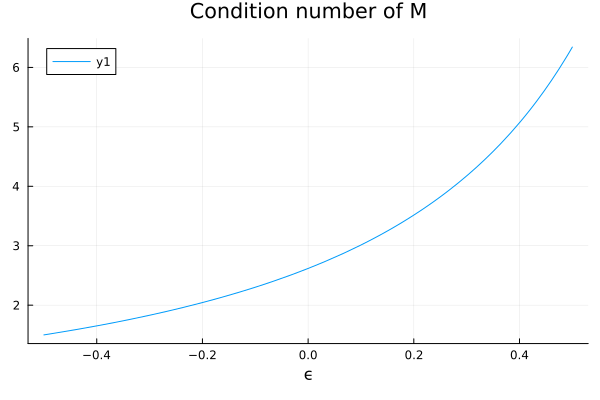

In [27]:
M(ϵ) = [-ϵ 1; 1 -1]
plot( ϵ->cond(M(ϵ)), -1/2, 1/2, title="Condition number of M", xlabel="ϵ")

2. If we did not use pivoting, the LU decomposition of $M(\epsilon)$ is 

$$
\begin{align}\nonumber
\begin{pmatrix}
1 & 0 \\ -\epsilon^{-1} & 1
\end{pmatrix}
\begin{pmatrix}
-\epsilon & 1 \\ 0 & \epsilon^{-1}-1
\end{pmatrix}.
\end{align}
$$

Both of these matrices are ill-conditioned. In the following, we can see that the condition numbers explode near $\epsilon \approx 0$. 

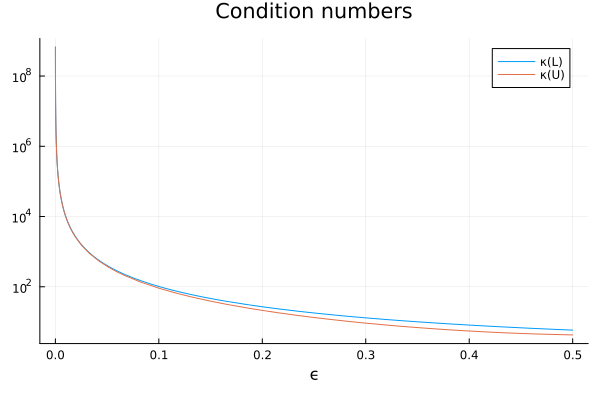

In [28]:
plot( ϵ->cond([1 0 ; -1/ϵ 1 ]), 0, 1/2, yaxis = :log10, title="Condition numbers", xlabel="ϵ", label="κ(L)")
plot!( ϵ->cond([-ϵ 1; 0 -1+1/ϵ]), 0, 1/2, label="κ(U)")

Notice this is not a problem with $M(\epsilon)$, but with our choice of LU decomposition. That is, without pivoting, our algorithm is unstable.

3. Using PLU decomposition, we arrive at 

$$
\begin{align}\nonumber
LU = \begin{pmatrix} -\epsilon & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 1 & -1 \\ 0 & 1-\epsilon \end{pmatrix} 
\end{align}
$$

(with $p(1) = 2$ and $p(2) = 1$). These factors are again well conditioned:

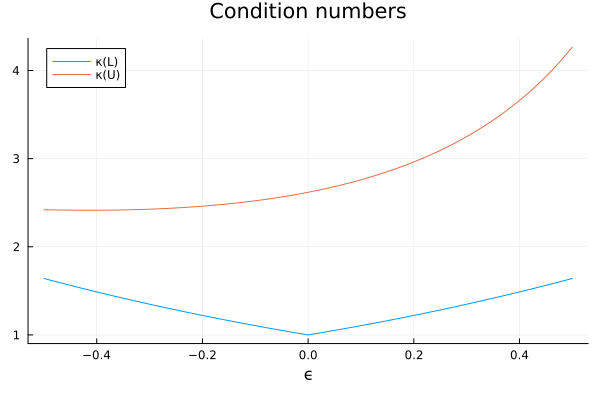

In [29]:
plot( ϵ->cond([-ϵ 1 ; 1 0 ]), -1/2, 1/2, title="Condition numbers", xlabel="ϵ", label="κ(L)")
plot!( ϵ->cond([1 -1; 0 1-ϵ]), -1/2, 1/2, label="κ(U)")

## Condition numbers of linear systems of equations

In order to fully understand the previous section, we need to make sense of the condition number $\kappa(A)$. Recall (@def-rel-condition-number) that when we were considering functions $f : \mathbb R \to \mathbb R$, the condition number was (approximately) the constant of proportionality between the relative error in the input to the relative error of the output. That is, if $x \approx \tilde{x}$ then, we have 

$$
\begin{align}\nonumber
\frac{|f(x)- f(\tilde{x})|}{|f(x)|} \approx \kappa_f(x) \frac{|x- \tilde{x}|}{|x|}.
\end{align}
$$

We now take this idea but the "input" is the vector $b$ and the "output" is $x$ solving the linear system $A x = b$. Again, the condition number measures how sensitive the solution $x$ is to errors in the data $b$. Roughly speaking, if the condition number is $10^\rho$, we expect to lose $\rho$ digits of accuracy when we go from $b$ to $x$. This made perfect sense on $\mathbb R$ (with the absolute value) but now we have many choices for the norm. We shall fix the Euclidean norm for the remainder of the course:

$$
\begin{align}\nonumber
|x| := \sqrt{\sum_{j=1}^n |x_j|^2}.
\end{align}
$$

We also need the corresponding *operator norm* on the space of matrices:

::: {#def-operator-norm name="Operator norm"}

$$
\begin{align}\nonumber
\|A\| := \max_{x\not=0} \frac{|Ax|}{|x|}. 
\end{align}
$$

:::

Notice that, we have $|Ax| \leq \|A\| |x|$ for all $x$. We are now ready to define the condition number of the matrix $A$ (or the corresponding linear system).

Suppose we have the exact data $b$ and exact solution $x$ (solving $Ax=b$) and we have the approximate data $\tilde{b}$ (for example, the floating point representation of $b$) and corresponding solution $\tilde{x}$ solving $A\tilde{x} = \tilde{b}$. First, notice that $|b| = |Ax| \leq \|A\| |x|$ and that $A(x - \tilde{x}) = b - \tilde{b}$ and so

$$
\begin{align}\nonumber
|x - \tilde{x}| \leq \|A^{-1}\| |b - \tilde{b}|.
\end{align}
$$

Therefore, we have 

$$
\begin{align}
\frac
{|x-\tilde{x}|/|x|}
{|b-\tilde{b}|/|b|}
%
= \frac
{|x-\tilde{x}|}
{|b-\tilde{b}|}
\frac
{|b|}
{|x|}
%
\leq \|A^{-1}\| \|A\|. 
\end{align}
$$ {#eq-l13-cond-bound}

::: {#def-condition-number-matrix name="Condition number of a matrix"}

The condition number of an invertible matrix $A$ is the right hand side of @eq-l13-cond-bound:
$$
\begin{align}\nonumber
\kappa(A) := \|A^{-1}\| \|A\|.
\end{align}
$$

:::

::: {#exr-l13-norms}

1. Use the definitions directly to show that the following matrices are ill-conditioned for small $\epsilon > 0$,
$$
\begin{align}\nonumber
\begin{pmatrix}
1 & 0 \\ -\epsilon^{-1} & 1
\end{pmatrix}, \qquad
\begin{pmatrix}
-\epsilon & 1 \\ 0 & \epsilon^{-1}-1
\end{pmatrix},
\end{align}
$$
2. Show that $\|A\| = \max_{|x|=1} |Ax|$, 
3. Show that $\|AB\| \leq \|A\|\|B\|$ and hence $\|A^k\| \leq \|A\|^k$, 
4. What is $\|D\|$ for diagonal $D$?
5. A real matrix $A$ is symmetric (i.e. $A^T = A$) if and only if there exists orthogonal $P$ (i.e. $P^{-1} = P^T$) and diagonal $\Lambda$ such that $A = P\Lambda P^T$. Show that the columns of $P$ are eigenvectors of $A$,
6. Show that, for symmetric matrices $A$, the operator norm $\|A\|$ is equal to $\max_i |\lambda_i|$ where $(\lambda_i)$ are the eigenvalues of $A$.

::: {.exercise-hint .draft style="display: none;"}

For 1, $\|A\| \geq |Ae_j|$ for each standard basis vector $e_j$; apply this to $A$ and to $A^{-1}$. For 6, use that $|Px| = |x|$ for orthogonal $P$.

:::

::: {.exercise-solution .draft style="display: none;"}

**1.** Let $0 < \epsilon < 1$. For $L_\epsilon = \begin{pmatrix} 1 & 0\\ -\epsilon^{-1} & 1\end{pmatrix}$ we have $L_\epsilon^{-1} = \begin{pmatrix} 1 & 0\\ \epsilon^{-1} & 1\end{pmatrix}$ and so
$$
\|L_\epsilon\| \geq |L_\epsilon e_1| = \sqrt{1 + \epsilon^{-2}}, \qquad \|L_\epsilon^{-1}\| \geq |L_\epsilon^{-1}e_1| = \sqrt{1+\epsilon^{-2}},
$$
which means $\kappa(L_\epsilon) \geq 1 + \epsilon^{-2} \to \infty$ as $\epsilon\to0$. For $U_\epsilon = \begin{pmatrix} -\epsilon & 1\\ 0 & \epsilon^{-1} - 1\end{pmatrix}$, we have
$$
U_\epsilon^{-1} = \begin{pmatrix} -\epsilon^{-1} & \frac{1}{1-\epsilon}\\ 0 & \frac{\epsilon}{1-\epsilon}\end{pmatrix}
$$
and so $\|U_\epsilon\| \geq |U_\epsilon e_2| > \epsilon^{-1} - 1$ and $\|U_\epsilon^{-1}\| \geq |U_\epsilon^{-1} e_1| = \epsilon^{-1}$. Therefore, $\kappa(U_\epsilon) > \epsilon^{-1}(\epsilon^{-1} - 1) \to\infty$. (In contrast, $\kappa(M(\epsilon)) \to \frac{3+\sqrt5}{2} \approx 2.618$ as $\epsilon \to 0$, by part 6.)

**2.** For $x\not= 0$, $\hat x := x/|x|$ satisfies $|\hat x| = 1$ and $\frac{|Ax|}{|x|} = |A\hat x|$. Therefore, the set of values $\{ |Ax|/|x| : x \not= 0 \}$ is equal to $\{ |Ay| : |y| = 1\}$ and so the maxima agree.

**3.** For all $x$, $|ABx| \leq \|A\|\,|Bx| \leq \|A\|\,\|B\|\,|x|$. Dividing by $|x|$ and maximising gives $\|AB\|\leq\|A\|\|B\|$. By induction, $\|A^{k}\| \leq \|A\|\,\|A^{k-1}\| \leq \|A\|^k$.

**4.** Let $D = \mathrm{diag}(d_1,\dots,d_n)$. Then $|Dx|^2 = \sum_i d_i^2x_i^2 \leq (\max_i |d_i|)^2|x|^2$ and so $\|D\| \leq \max_i|d_i|$. Choosing $x = e_{i^\star}$ where $|d_{i^\star}| = \max_i |d_i|$ shows that $\|D\| = \max_i|d_i|$.

**5.** If $A = P\Lambda P^T$ with $P^T = P^{-1}$, then $AP = P\Lambda$. The $i$-th column of this equation reads $A p_i = \Lambda_{ii} p_i$ where $p_i$ is the $i$-th column of $P$. Since $P$ is invertible, $p_i \not= 0$ and so $p_i$ is an eigenvector of $A$ with eigenvalue $\lambda_i = \Lambda_{ii}$. Moreover, $\det(\lambda I - A) = \det\big(P(\lambda I - \Lambda)P^T\big) = \prod_i(\lambda - \lambda_i)$, so these are all of the eigenvalues of $A$.

**6.** For any $x$, let $y = P^Tx$. Then $|y|^2 = x^T P P^T x = |x|^2$ and $|Ax| = |P\Lambda y| = |\Lambda y|$. As $x$ runs over all nonzero vectors, so does $y$, and therefore $\|A\| = \|\Lambda\| = \max_i|\lambda_i|$ by 4 and 5.

(The same proof works for *normal* matrices ($A^*A = AA^*$) over $\mathbb C$, which are exactly the matrices $A = U\Lambda U^*$ with $U$ unitary.)

:::

:::

## Next time.... 

- Linear least squares: overdetermined systems $Ax = b$ with $A \in \mathbb R^{m\times n}$, $m > n$,
- The normal equations and fitting data,
- QR decomposition.

::: {.callout-tip}
# TO-DO

* Exercises throughout the notes,
* (Sign-up to office hours if you like)

:::

## Extra exercises

::: {#exr-l13-plu-hand}

Compute (by hand) the PLU decomposition of
$$
\begin{align}\nonumber
C = \begin{pmatrix} 0 & 6 & -10 \\ 15 & 0 & -6 \\ 5 & 1 & -4 \end{pmatrix}
\end{align}
$$
using the largest pivot at each step, and check your answer with `lu(C)`. Use your answer to compute $\det C$.

::: {.exercise-solution .draft style="display: none;"}

*Step 1.* The largest entry in column 1 is $15$, so $p(1) = 2$, $u_1 = (15, 0, -6)$ and $\ell_1 = (0, 1, \frac13)^\intercal$. Then $A^{(2)} = C - \ell_1 u_1$ has rows $(0,6,-10)$, $(0,0,0)$, $(0,1,-2)$.

*Step 2.* The largest entry in column 2 is $6$, so $p(2) = 1$, $u_2 = (0,6,-10)$ and $\ell_2 = (1, 0, \frac16)^\intercal$. Then $A^{(3)} = A^{(2)} - \ell_2 u_2$ has only one nonzero entry: $A^{(3)}_{33} = -2 + \frac{10}{6} = -\frac13$.

*Step 3.* $p(3) = 3$, $u_3 = (0, 0, -\frac13)$ and $\ell_3 = (0,0,1)^\intercal$. Therefore, $p = (2,1,3)$ and
$$
PL = \begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ \frac13 & \frac16 & 1 \end{pmatrix}, \qquad
U = \begin{pmatrix} 15 & 0 & -6 \\ 0 & 6 & -10 \\ 0 & 0 & -\frac13 \end{pmatrix},
$$
which agrees with `lu(C)` (`F.L` is $PL$, `F.U` is $U$ and `F.p` is $p$). Since $PC = (PL)U$ and $\det P = -1$ (one swap), $\det C = -15 \cdot 6 \cdot (-\frac13) = 30$.

:::

:::

::: {#exr-l13-cond-properties}

Let $A$ be invertible.

1. Show that $\kappa(A) \geq 1$ and that $\kappa(\alpha A) = \kappa(A)$ for all $\alpha \not= 0$,
2. Show that, if $A$ is symmetric with eigenvalues $(\lambda_i)$, then $\kappa(A) = \max_i |\lambda_i| / \min_i |\lambda_i|$,
3. Compute $\kappa(A)$ for $A = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$ and check your answer with `cond(A)`.

::: {.exercise-solution .draft style="display: none;"}

1. By @exr-l13-norms, $1 = \|I\| = \|A A^{-1}\| \leq \|A\| \|A^{-1}\| = \kappa(A)$. Also $\|\alpha A\| = |\alpha| \|A\|$ and $(\alpha A)^{-1} = \alpha^{-1} A^{-1}$, so $\kappa(\alpha A) = |\alpha| |\alpha|^{-1} \|A\|\|A^{-1}\| = \kappa(A)$.

2. If $A = P\Lambda P^T$, then $A^{-1} = P\Lambda^{-1}P^T$ is symmetric with eigenvalues $(\lambda_i^{-1})$. By @exr-l13-norms, $\|A\| = \max_i |\lambda_i|$ and $\|A^{-1}\| = \max_i |\lambda_i|^{-1} = 1/\min_i |\lambda_i|$.

3. The eigenvalues are $3$ (eigenvector $(1,1)^\intercal$) and $1$ (eigenvector $(1,-1)^\intercal$), so $\kappa(A) = 3$.

:::

:::